In [3]:
import ccxt
import pandas as pd
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import schedule
import time
from IPython.display import display, clear_output
import threading

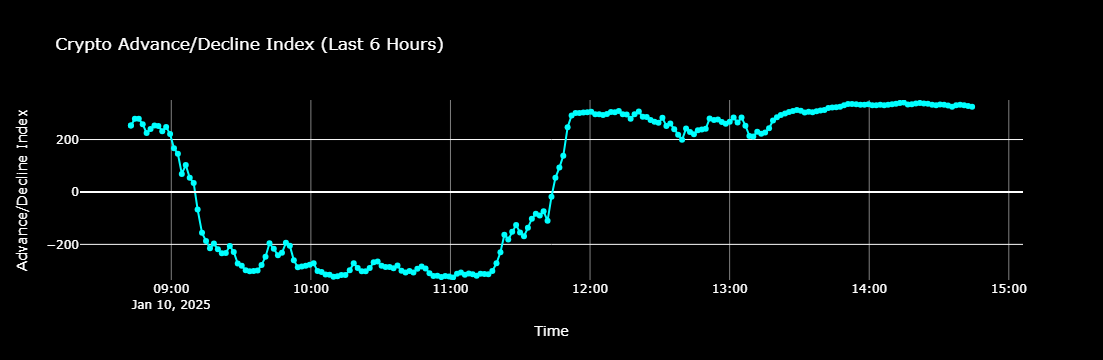

In [11]:

# Initialize the exchange
exchange = ccxt.binance()

# Load markets to ensure symbols are available
exchange.load_markets()

# Define the global DataFrame for Advance/Decline data
combined_df = pd.DataFrame(columns=['timestamp', 'adv_decl_index'])

# Function to fetch percentage change for each symbol directly from Binance
def fetch_adv_decl_data(symbol):
    ticker = exchange.fetch_ticker(symbol)
    # Get the percentage change directly from the ticker
    percentage_change = ticker.get('percentage', None)
    return percentage_change

# Create the figure widget
fig = make_subplots(rows=1, cols=1)

def update_chart():
    global combined_df  # Ensure we're modifying the global DataFrame

    # Fetch all USDT-paired symbols
    tickers = exchange.fetch_tickers()
    usdt_pairs = [symbol for symbol in tickers if symbol.endswith('/USDT')]

    # Calculate advance/decline for each symbol based on percentage change
    adv_decl_points = []
    for symbol in usdt_pairs:
        # Fetch percentage change for the symbol
        percentage_change = fetch_adv_decl_data(symbol)
        
        # Determine advance/decline: positive is advance, negative is decline
        if percentage_change is not None:
            advance = 1 if percentage_change > 0 else -1 if percentage_change < 0 else 0
            adv_decl_points.append(advance)

    # Calculate the total advance/decline index
    adv_decl_index = sum(adv_decl_points)

    # Add the index value to a DataFrame with timestamps
    timestamp = pd.Timestamp.now()
    new_data = pd.DataFrame({'timestamp': [timestamp], 'adv_decl_index': [adv_decl_index]})
    
    # Combine new data into the main DataFrame (append new rows to existing data)
    combined_df = pd.concat([combined_df, new_data], ignore_index=True)

    # Create the figure
    fig.data = []  # Clear previous traces

    # Add line trace for Advance/Decline Index
    line = go.Scatter(
        x=combined_df['timestamp'],
        y=combined_df['adv_decl_index'],
        mode='lines+markers',
        line=dict(color='cyan', width=2),
        marker=dict(size=6, color='cyan'),
        name='Advance/Decline Index'
    )

    fig.add_trace(line, row=1, col=1)

    # Add horizontal line at zero
    fig.add_hline(y=0, line=dict(color='white', width=1, dash='dot'), row=1, col=1)

    # Update layout for better visualization
    fig.update_layout(
        title='Crypto Advance/Decline Index (Last 6 Hours)',
        xaxis_title='Time',
        yaxis_title='Advance/Decline Index',
        xaxis_rangeslider_visible=False,
        yaxis=dict(
            range=[combined_df['adv_decl_index'].min() - 10, combined_df['adv_decl_index'].max() + 10]  # Dynamic range
        ),
        plot_bgcolor='black',
        paper_bgcolor='black',
        font=dict(color='white'),
        xaxis=dict(gridcolor='gray')
    )

    # Clear the previous output and display the updated figure
    clear_output(wait=True)
    display(fig)

# Schedule the chart to be updated every minute
schedule.every(1).minutes.do(update_chart)

def run_scheduler():
    start_time = time.time()
    while True:
        # Check if 6 hours have passed
        if time.time() - start_time >= 6 * 60 * 60:
            break
        schedule.run_pending()
        time.sleep(1)

# Start the scheduler in a separate thread
scheduler_thread = threading.Thread(target=run_scheduler)
scheduler_thread.start()

# Initial chart update
update_chart()

# Join the scheduler thread to ensure it completes
scheduler_thread.join()
